# Sprint 3 — Advanced Statistics & Feature Engineering
## Bank Marketing Campaign & Customer Response Analytics

**Sprint goal:** move from *"I found a pattern"* (Sprint 2) to *"is the pattern statistically supported, how precisely is it measured, and do better-designed features improve understanding?"*, then turn the evidence into recommendations.

**Files used:** `bank_core_cleaned.csv` (real banking data), `bank_roi_proxy.csv` (assumption-based cost/value: 0.50 per call-minute, 200 per subscriber), and the real 88-campaign marketing table (`Marketing Campaign Performance and ROI Dataset.xlsx`, analysed separately, no customer key).
**Files produced:** `bank_features_engineered.csv`, `feature_documentation.csv`.

### Ground rules for reading this notebook
1. **Significance is easy with 11,162 rows.** Almost any difference will give a tiny p-value, so every test also reports an **effect size** (Cramér's V, Cohen's d, probability of superiority, η²). A result is only called *meaningful* when the effect is also reasonably large.
2. **Skewed data → rank tests first.** Balance, duration and campaign are heavily right-skewed (Section 1), so Mann–Whitney / Kruskal–Wallis are the primary tests; Welch t and ANOVA are shown for comparison.
3. **Exploration and testing use the same data.** The patterns tested here were first spotted in Sprint 2, so p-values are somewhat optimistic. To limit this, Section 5 evaluates features on **held-out data** and 14 chi-square tests are checked against a Bonferroni-adjusted threshold.
4. **Association is not causation**, and `duration` is known only after the call, so it is never used to choose whom to call.
5. α = 0.05 for every test.

## 0. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
rng = np.random.default_rng(42)           # fixed seed -> every bootstrap / split below is reproducible

DATA_DIR = '.'    # folder holding the project files
core = pd.read_csv(f'{DATA_DIR}/bank_core_cleaned.csv')
roi  = pd.read_csv(f'{DATA_DIR}/bank_roi_proxy.csv')
df = core.merge(roi, on='customer_id', how='inner', validate='one_to_one')
df['deposit_flag'] = (df.deposit == 'yes').astype(int)
BASE = df.deposit_flag.mean() * 100
print('merged:', df.shape, f'| baseline response rate {BASE:.1f}%')

# ---- helper functions used throughout the notebook ----
def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion (better than the normal formula for small n or extreme p)."""
    p = k / n; d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

def fmt_p(p):
    return '< 1e-300' if p < 1e-300 else f'{p:.2e}' if p < 0.001 else f'{p:.4f}'

# EDA bands carried over from Sprint 2 (formally documented in section 5)
df['age_group'] = pd.cut(df.age, [17, 29, 39, 49, 59, 100], labels=['<30', '30-39', '40-49', '50-59', '60+']).astype(str)
df['balance_tier'] = pd.cut(df.balance, [-np.inf, -1, 500, 2000, np.inf], labels=['Overdrawn', 'Low', 'Medium', 'High']).astype(str)
df['contact_frequency_band'] = pd.cut(df.campaign, [0, 1, 2, 3, 5, np.inf], labels=['1', '2', '3', '4-5', '6+']).astype(str)
df['debt_status'] = np.select([(df.housing == 'yes') & (df.loan == 'yes'), df.housing == 'yes', df.loan == 'yes'],
                              ['Housing + personal', 'Housing only', 'Personal only'], default='No loans')

merged: (11162, 24) | baseline response rate 47.4%


## 1. Statistical analysis

             mean  median      std      IQR     P5      P95  skew  excess_kurtosis  outliers_1_5IQR  outlier_pct
variable                                                                                                        
age         41.19    39.0    11.83    17.00  26.00    61.00  0.88             0.68              167         1.50
balance   1519.69   551.0  3215.91  1566.00 -49.95  6004.95  8.28           128.39             1056         9.46
duration   370.50   255.0   345.11   351.00  52.00  1074.00  2.17             7.48              663         5.94
campaign     2.51     2.0     2.72     2.00   1.00     7.00  5.55            57.44              601         5.38
pdays       51.33    -1.0   108.76    21.75  -1.00   326.00  2.45             6.84             2750        24.64
previous     0.83     0.0     2.29     1.00   0.00     5.00  7.34           106.20             1258        11.27

Covariance matrix (raw units - depends on scale, so read the sign and use correlation for stren

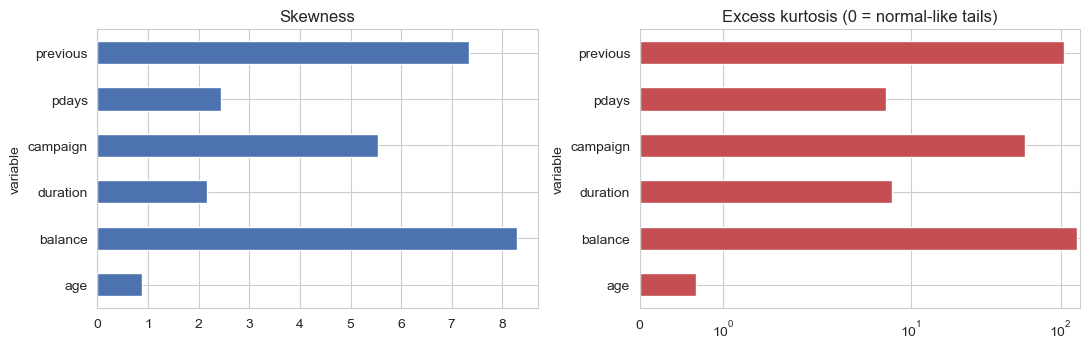

In [2]:
num = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
rows = []
for c in num:
    s = df[c]; q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append(dict(variable=c, mean=s.mean(), median=s.median(), std=s.std(), IQR=iqr, P5=s.quantile(.05), P95=s.quantile(.95),
                     skew=s.skew(), excess_kurtosis=s.kurt(), outliers_1_5IQR=int(((s < lo) | (s > hi)).sum()),
                     outlier_pct=((s < lo) | (s > hi)).mean() * 100))
sd = pd.DataFrame(rows).set_index('variable').round(2)
print(sd.to_string())
print('\nCovariance matrix (raw units - depends on scale, so read the sign and use correlation for strength):')
print(df[['age', 'balance', 'duration', 'campaign']].cov().round(0).to_string())
print('\nSpearman correlation with subscribing (rho, p-value):')
for c in num:
    r, p = stats.spearmanr(df[c], df.deposit_flag); print(f'  {c:9s} rho = {r:+.3f}   p = {fmt_p(p)}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sd['skew'].plot.barh(ax=ax[0], color='#4C72B0'); ax[0].set_title('Skewness')
sd['excess_kurtosis'].plot.barh(ax=ax[1], color='#C44E52'); ax[1].set_title('Excess kurtosis (0 = normal-like tails)'); ax[1].set_xscale('symlog')
plt.tight_layout(); plt.show()

**Observation**
* Skewness and kurtosis: `balance` is extreme (skew **8.28**, excess kurtosis **128**), as are `previous` (7.34 / 106) and `campaign` (5.55 / 57). `duration` is moderately skewed (2.17 / 7.5). `age` is close to symmetric (0.88 / 0.68).
* The IQR rule flags 9.5% of balances (1,056 customers), 5.9% of durations and 5.4% of campaign counts as outliers. For `pdays`, the 24.6% "outliers" are an artefact: the code −1 (never contacted) makes the IQR meaningless, so this column should be analysed through the `previously_contacted` flag instead.
* Covariance: balance moves with age (+4,183) and with duration (+25,788); campaign (number of calls) moves slightly *against* duration (−39). Covariances depend on units, so strength is read from correlations.
* Spearman correlation with subscribing: duration **+0.52**, previous contacts +0.23, pdays +0.21, balance +0.16, campaign **−0.13**; **age −0.01 (p = 0.24, not significant)**. All except age are statistically significant (p < 1e-40).

**Interpretation:** the tails are heavy, so means and ordinary standard deviations mislead for balance, campaign and previous; medians and IQR describe the typical customer. Age shows *no* monotonic relationship with subscribing, but Sprint 2 found a U-shape, which a rank correlation cannot detect. This is the reason age is converted into bands in Section 4.

**Business insight:** reports to management should quote medians (balance 551, not 1,520) and percentile ranges. Of the numeric fields, only call duration relates strongly to the outcome, and it is unavailable before dialling, so pre-call targeting must lean on categorical history and profile (next sections).

## 2. Hypothesis testing

**Choosing the test:** two categorical variables → chi-square test of independence (effect size Cramér's V). A numeric variable in two groups → Mann–Whitney (primary, because of skew) with Welch t for comparison. A numeric variable across 3+ groups → Kruskal–Wallis (primary) with one-way ANOVA for comparison. Every block below prints H0, H1, the test statistic, the p-value and the decision; the business interpretation is written after the output.

### 2.1 Chi-square: are categorical factors associated with subscribing?

In [3]:
def chi_test(a, data=None, b='deposit'):
    data = df if data is None else data
    ct = pd.crosstab(data[a], data[b])
    chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    return ct, dict(variable=a, chi2=chi2, dof=dof, p=p, cramers_v=np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), min_expected=exp.min())

def report_chi(a, h0, h1):
    ct, r = chi_test(a)
    print(f'===== {a} vs deposit =====')
    print('H0:', h0); print('H1:', h1)
    print((pd.crosstab(df[a], df.deposit, normalize='index') * 100).round(1).assign(customers=ct.sum(axis=1)).to_string())
    print(f"chi-square = {r['chi2']:.1f} | dof = {r['dof']} | p = {fmt_p(r['p'])} | Cramer's V = {r['cramers_v']:.3f} | smallest expected count = {r['min_expected']:.0f} (rule: >= 5)")
    print('Decision at alpha = 0.05:', 'REJECT H0' if r['p'] < 0.05 else 'FAIL TO REJECT H0'); print()

report_chi('contact', 'Contact method and deposit outcome are independent.', 'Contact method and deposit outcome are associated.')
report_chi('poutcome', 'Previous campaign outcome and deposit outcome are independent.', 'They are associated.')
report_chi('housing', 'Having a housing loan and deposit outcome are independent.', 'They are associated.')

===== contact vs deposit =====
H0: Contact method and deposit outcome are independent.
H1: Contact method and deposit outcome are associated.
deposit      no   yes  customers
contact                         
cellular   45.8  54.2       7971
telephone  49.5  50.5        768
unknown    76.2  23.8       2423
chi-square = 693.5 | dof = 2 | p = 2.51e-151 | Cramer's V = 0.249 | smallest expected count = 364 (rule: >= 5)
Decision at alpha = 0.05: REJECT H0

===== poutcome vs deposit =====
H0: Previous campaign outcome and deposit outcome are independent.
H1: They are associated.
deposit     no   yes  customers
poutcome                       
failure   50.1  49.9       1212
other     43.0  57.0        530
success    8.7  91.3       1063
unknown   59.2  40.8       8357
chi-square = 991.3 | dof = 3 | p = 1.40e-214 | Cramer's V = 0.298 | smallest expected count = 251 (rule: >= 5)
Decision at alpha = 0.05: REJECT H0

===== housing vs deposit =====
H0: Having a housing loan and deposit outcome are 

**Business interpretation**
* **Contact method (χ² = 693.5, dof 2, p = 2.5e-151, V = 0.25):** reject H0. Customers with an *unknown* contact method subscribe at 23.8% vs 54.2% by cellular. The channel recorded matters, or, more likely, "unknown" marks a weaker group of leads or a record-keeping gap (see Section 6).
* **Previous outcome (χ² = 991.3, dof 3, p = 1.4e-214, V = 0.30):** reject H0. A previous success converts at 91.3% vs 40.8% for customers with no history; a previous failure is still 49.9%, above the overall rate.
* **Housing loan (χ² = 464.0, dof 1, p = 6.5e-103, V = 0.20):** reject H0. 57.0% without a housing loan vs 36.6% with one.

All expected counts are far above 5, so the chi-square assumptions hold.

### 2.2 All categorical factors at once (with a multiple-testing check)
H0 for every row: *the variable and deposit outcome are independent.* H1: *they are associated.*

14 chi-square tests -> Bonferroni-adjusted alpha = 0.0036

                            chi2  dof          p  cramers_v  min_expected  significant_0.05  significant_bonferroni effect_size
variable                                                                                                                       
month                   1046.775   11  1.64e-217      0.306        52.122              True                    True      medium
poutcome                 991.290    3  1.40e-214      0.298       251.135              True                    True       small
contact                  693.541    2  2.51e-151      0.249       363.909              True                    True       small
debt_status              609.225    3  1.01e-131      0.234       296.150              True                    True       small
previously_contacted     594.840    1  2.22e-131      0.231      1344.757              True                    True       small
housing                  464.007    1  6.46e-

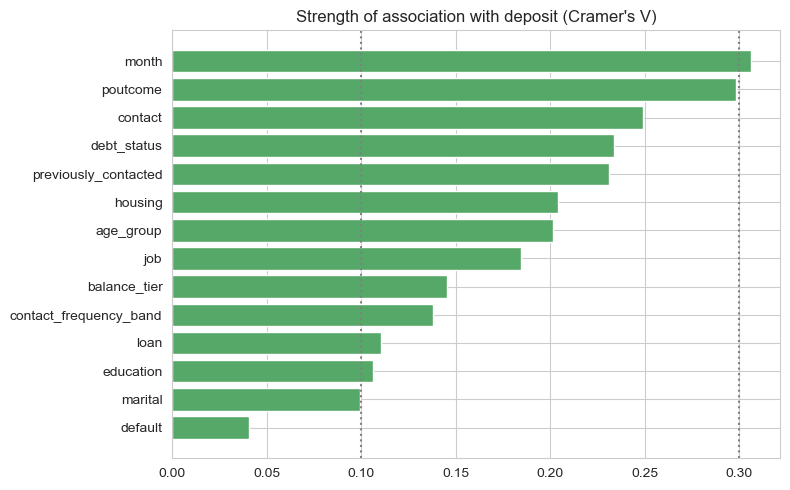

In [4]:
df['previously_contacted'] = np.where(df.pdays > -1, 'Yes', 'No')
vars_ = ['job', 'education', 'marital', 'default', 'housing', 'loan', 'debt_status', 'contact', 'poutcome', 'previously_contacted',
         'month', 'age_group', 'balance_tier', 'contact_frequency_band']
res = pd.DataFrame([chi_test(v)[1] for v in vars_]).set_index('variable')
alpha_adj = 0.05 / len(res)
res['significant_0.05'] = res.p < 0.05
res[f'significant_bonferroni'] = res.p < alpha_adj
res['effect_size'] = pd.cut(res.cramers_v, [0, .1, .3, .5, 1], labels=['negligible', 'small', 'medium', 'large'])
res['p'] = res.p.apply(fmt_p)
print(f'{len(res)} chi-square tests -> Bonferroni-adjusted alpha = {alpha_adj:.4f}\n')
print(res.sort_values('cramers_v', ascending=False).round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 5))
t = res.sort_values('cramers_v'); ax.barh(t.index, t.cramers_v, color='#55A868')
for x in (.1, .3): ax.axvline(x, color='grey', ls=':')
ax.set_title("Strength of association with deposit (Cramer's V)"); plt.tight_layout(); plt.show()

**Observation:** all 14 tests reject H0, and all 14 survive the Bonferroni threshold (0.0036). The strongest associations are `month` (V = 0.31), `poutcome` (0.30), `contact` (0.25), `debt_status` (0.23) and `previously_contacted` (0.23). `marital` (0.10) and especially `default` (0.04) are statistically significant but their effect is negligible.

**Interpretation:** with this many customers, significance alone is not informative: effect size separates the useful factors from the trivial ones. The Cramér's V labels use common rule-of-thumb cut-offs (designed for 2×2 tables), so treat them as guidance, not strict categories.

**Business insight:** campaign history, contact channel, debt load and timing are the factors worth building call strategy around. `default` and `marital` can be ignored for targeting. `month` is the strongest association, but it is entangled with campaign volume and contact method (Sprint 2), so it should not be used on its own to move budget.

### 2.3 Subscribers vs non-subscribers: do numeric characteristics differ?

In [5]:
def compare_groups(col, B=2000):
    y = df.loc[df.deposit == 'yes', col].values.astype(float); n = df.loc[df.deposit == 'no', col].values.astype(float)
    t, pt = stats.ttest_ind(y, n, equal_var=False)
    u, pu = stats.mannwhitneyu(y, n, alternative='two-sided')
    lev = stats.levene(y, n, center='median')
    d = (y.mean() - n.mean()) / np.sqrt((y.var(ddof=1) + n.var(ddof=1)) / 2)
    auc = u / (len(y) * len(n))
    diffs = np.array([np.median(rng.choice(y, len(y))) - np.median(rng.choice(n, len(n))) for _ in range(B)])
    ci = np.percentile(diffs, [2.5, 97.5])
    print(f'===== {col}: subscribers (n={len(y)}) vs non-subscribers (n={len(n)}) =====')
    print(f'H0: {col} has the same distribution / mean in both groups.   H1: it differs.')
    print(f'  skew yes/no = {stats.skew(y):.1f} / {stats.skew(n):.1f}  -> not normal, so the rank test is the primary result; Welch t is shown for completeness')
    print(f'  means  yes {y.mean():,.1f} vs no {n.mean():,.1f} | medians yes {np.median(y):,.0f} vs no {np.median(n):,.0f}')
    print(f'  Levene (equal spread?) p = {fmt_p(lev.pvalue)}')
    print(f'  Welch t = {t:.2f}, p = {fmt_p(pt)} | Cohen d = {d:.2f}')
    print(f'  Mann-Whitney U = {u:,.0f}, p = {fmt_p(pu)} | P(random subscriber > random non-subscriber) = {auc:.3f}')
    print(f'  95% bootstrap CI for difference in medians: [{ci[0]:,.0f}, {ci[1]:,.0f}]')
    print('  Decision at 0.05:', 'REJECT H0' if pu < 0.05 else 'FAIL TO REJECT H0'); print()
for c in ['duration', 'balance', 'age', 'campaign']:
    compare_groups(c)

===== duration: subscribers (n=5289) vs non-subscribers (n=5873) =====
H0: duration has the same distribution / mean in both groups.   H1: it differs.
  skew yes/no = 1.7 / 3.0  -> not normal, so the rank test is the primary result; Welch t is shown for completeness
  means  yes 533.8 vs no 223.4 | medians yes 418 vs no 165
  Levene (equal spread?) p = 1.93e-256
  Welch t = 51.54, p = < 1e-300 | Cohen d = 0.99
  Mann-Whitney U = 24,943,446, p = < 1e-300 | P(random subscriber > random non-subscriber) = 0.803
  95% bootstrap CI for difference in medians: [243, 269]
  Decision at 0.05: REJECT H0

===== balance: subscribers (n=5289) vs non-subscribers (n=5873) =====
H0: balance has the same distribution / mean in both groups.   H1: it differs.
  skew yes/no = 8.5 / 7.8  -> not normal, so the rank test is the primary result; Welch t is shown for completeness
  means  yes 1,796.7 vs no 1,270.3 | medians yes 718 vs no 431
  Levene (equal spread?) p = 2.94e-10
  Welch t = 8.58, p = 1.07e-17 | 

**Business interpretation**
* **Call duration:** reject H0, a very large effect (Cohen's d = 0.99; a random subscriber has a longer call than a random non-subscriber 80% of the time). Median gap 243–269 seconds (95% CI). Duration separates the groups strongly, but it is only observable after the call.
* **Account balance:** reject H0, but the effect is small (d = 0.16; probability of superiority 59%). Subscribers hold a median of 718 vs 431; the median gap is 239–347. Wealthier customers respond somewhat more; balance is a modest signal, not a decisive one.
* **Age:** the two tests **disagree**. Welch t-test is "significant" (p = 0.0002) because the means differ by 0.8 years, while the Mann–Whitney test is not (p = 0.24) and the median gap CI includes 0. The effect is trivial (d = 0.07). Age matters only through its U-shape (young and old respond well, middle ages less), which neither test can capture; that is why `age_group` is engineered.
* **Number of calls:** reject H0 (d = −0.26, p ≈ 1e-41). Subscribers received fewer calls on average (2.1 vs 2.8), even though both medians are 2, so the difference sits in the long tail of heavily-called customers.

**Business insight:** the only strong numeric separator is call quality; for the rest, differences are real but modest, so no single numeric field should drive targeting.

### 2.4 ANOVA / Kruskal–Wallis: differences across 3+ groups

In [6]:
def anova_kruskal(values, groups, label):
    g = [values[groups == k].values for k in groups.unique() if (groups == k).sum() >= 5]
    F, pF = stats.f_oneway(*g); H, pH = stats.kruskal(*g)
    allv = np.concatenate(g); sst = ((allv - allv.mean())**2).sum(); ssb = sum(len(x) * (x.mean() - allv.mean())**2 for x in g)
    print(f'===== {label} ({len(g)} groups, n = {len(allv):,}) =====')
    print(f'  one-way ANOVA: F = {F:.2f}, p = {fmt_p(pF)}, eta-squared = {ssb / sst:.3f}')
    print(f'  Kruskal-Wallis: H = {H:.1f}, p = {fmt_p(pH)}')
    print('  Decision at 0.05 (Kruskal-Wallis is primary because the data are skewed):', 'REJECT H0' if pH < 0.05 else 'FAIL TO REJECT H0'); print()

print('Q1. H0: median/mean account balance is the same across all job groups.  H1: at least one job group differs.')
anova_kruskal(df.balance, df.job, 'balance across job groups')
print(df.groupby('job').balance.median().sort_values(ascending=False).round(0).to_string(), '\n')
print('Q2. H0: call duration is the same across contact methods.  H1: at least one differs.')
anova_kruskal(df.duration, df.contact, 'call duration across contact methods')
print(df.groupby('contact').duration.median().round(0).to_string())

Q1. H0: median/mean account balance is the same across all job groups.  H1: at least one job group differs.
===== balance across job groups (12 groups, n = 11,162) =====
  one-way ANOVA: F = 12.63, p = 3.91e-24, eta-squared = 0.012
  Kruskal-Wallis: H = 192.2, p = 3.01e-35
  Decision at 0.05 (Kruskal-Wallis is primary because the data are skewed): REJECT H0

job
retired          1084.0
unemployed        622.0
management        616.0
unknown           578.0
self-employed     574.0
technician        550.0
student           522.0
blue-collar       486.0
admin.            479.0
housemaid         444.0
entrepreneur      434.0
services          425.0 

Q2. H0: call duration is the same across contact methods.  H1: at least one differs.
===== call duration across contact methods (3 groups, n = 11,162) =====
  one-way ANOVA: F = 2.48, p = 0.0839, eta-squared = 0.000
  Kruskal-Wallis: H = 55.9, p = 7.19e-13
  Decision at 0.05 (Kruskal-Wallis is primary because the data are skewed): REJECT H0

c

**Business interpretation**
* **Balance across jobs:** reject H0 (Kruskal–Wallis H = 192.2, p = 3e-35). Retirees have the highest median balance (1,084), and services/entrepreneurs/housemaids the lowest (about 425–445). But job explains only about **1.2%** of the variation in balance (η² = 0.012): groups differ, yet most of the spread is *within* each job.
* **Call duration across contact methods:** the two tests disagree (ANOVA p = 0.084, Kruskal–Wallis p = 7e-13). Medians are 262 s (cellular), 245 s (telephone) and 229 s (unknown); the difference is real but only about 30 seconds and explains ~0% of the variation (η² ≈ 0). Calls do not meaningfully last longer on one channel, so channel differences in response are *not* explained by call length.

**Business insight:** job is a weak proxy for wealth, so job alone should not be used as a stand-in for financial capacity (use balance itself or `balance_tier`).

### 2.5 Do the real marketing channels differ in ROI? (closes the Sprint 2 question)

In [7]:
camp = pd.read_excel(f'{DATA_DIR}/Marketing Campaign Performance and ROI Dataset.xlsx', sheet_name='Marketing Campaign Performance ')
camp.columns = camp.columns.str.strip()
camp['Marketing_channel'] = camp['Marketing_channel'].fillna('Unknown')
camp['roi_ratio'] = (camp.Revenue - camp.Spend) / camp.Spend
named = camp[camp.Marketing_channel != 'Unknown'].copy()
named['log_roi'] = np.log1p(named.roi_ratio)          # ROI ratio > -1 always, so log1p is defined and tames the huge right skew
print('Q3. H0: campaign ROI is the same across the five named marketing channels.  H1: at least one channel differs.')
print(named.groupby('Marketing_channel').agg(campaigns=('roi_ratio', 'size'), median_roi_pct=('roi_ratio', lambda s: s.median() * 100)).round(0).to_string(), '\n')
anova_kruskal(named.log_roi, named.Marketing_channel, 'log(1+ROI) across marketing channels')

Q3. H0: campaign ROI is the same across the five named marketing channels.  H1: at least one channel differs.
                   campaigns  median_roi_pct
Marketing_channel                           
Email                     11           271.0
Paid Search               18           237.0
Ppc                       22           331.0
Referral                  16           304.0
Social Media              16           380.0 

===== log(1+ROI) across marketing channels (5 groups, n = 83) =====
  one-way ANOVA: F = 0.32, p = 0.8620, eta-squared = 0.016
  Kruskal-Wallis: H = 2.0, p = 0.7306
  Decision at 0.05 (Kruskal-Wallis is primary because the data are skewed): FAIL TO REJECT H0



**Business interpretation:** **fail to reject H0** (ANOVA p = 0.86, Kruskal–Wallis p = 0.73). Social Media and PPC look best and Paid Search weakest in Sprint 2, but with only 11–22 campaigns per channel and very variable campaign results, the data do **not** show that the channels truly differ in ROI. The ranking could be chance.

**Business insight:** do not reallocate marketing budget purely because one channel ranks first in this table. Collect more campaigns (or run randomised budget tests) before acting. This test uses the 83 campaigns with a known channel; the 5 without a channel are excluded.

### Hypothesis-testing report (summary)
| # | Test | H0 | Statistic | p-value | Decision | Business meaning |
|---|---|---|---|---|---|---|
| 1 | Chi-square: contact × deposit | independent | χ² = 693.5 (2) | 2.5e-151 | Reject | Unknown contact channel → much lower response |
| 2 | Chi-square: previous outcome × deposit | independent | χ² = 991.3 (3) | 1.4e-214 | Reject | Past success → 91% convert |
| 3 | Chi-square: housing loan × deposit | independent | χ² = 464.0 (1) | 6.5e-103 | Reject | Housing loan → 20 points lower |
| 4 | 11 more chi-square tests (Section 2.2) | independent | see table | all < 1e-4 | Reject all | Effect sizes separate useful from trivial |
| 5 | Mann–Whitney: duration | same distribution | U = 24.9M | < 1e-300 | Reject | Large effect, post-call only |
| 6 | Mann–Whitney: balance | same distribution | U = 18.3M | 3.1e-61 | Reject | Small effect |
| 7 | Mann–Whitney: age | same distribution | U = 15.3M | 0.24 | **Fail to reject** | No age gap (U-shape missed) |
| 8 | Mann–Whitney: campaign | same distribution | U = 13.4M | 9.3e-41 | Reject | Fewer calls among subscribers |
| 9 | Kruskal–Wallis: balance × job | same | H = 192.2 | 3.0e-35 | Reject | Statistically yes, practically small (η² 0.012) |
| 10 | Kruskal–Wallis: duration × contact | same | H = 55.9 | 7.2e-13 | Reject | ~30 s difference only |
| 11 | Kruskal–Wallis: ROI × channel | same | H = 2.0 | 0.73 | **Fail to reject** | Channel differences not established |

## 3. Confidence interval analysis

### 3.1 Response rates (Wilson 95% intervals)

Overall response rate: 47.4%  95% CI [46.5%, 48.3%]  (n = 11,162, width 1.9 points)

                            customers  rate  ci_low  ci_high  ci_width
segment                                                               
All customers                   11162  47.4    46.5     48.3       1.9
Previous campaign: success       1063  91.3    89.5     92.9       3.4
Previous campaign: failure       1212  49.9    47.1     52.7       5.6
No previous history              8357  40.8    39.8     41.9       2.1
No housing loan                  5881  57.0    55.8     58.3       2.5
Housing loan                     5281  36.6    35.4     37.9       2.6
Contact: cellular                7971  54.2    53.2     55.3       2.2
Contact: unknown                 2423  23.8    22.2     25.6       3.4
1 call                           4794  53.4    52.0     54.8       2.8
6+ calls                          864  29.3    26.3     32.4       6.1
Debt-free, age 60+                660  79.4    76.1     82.3   

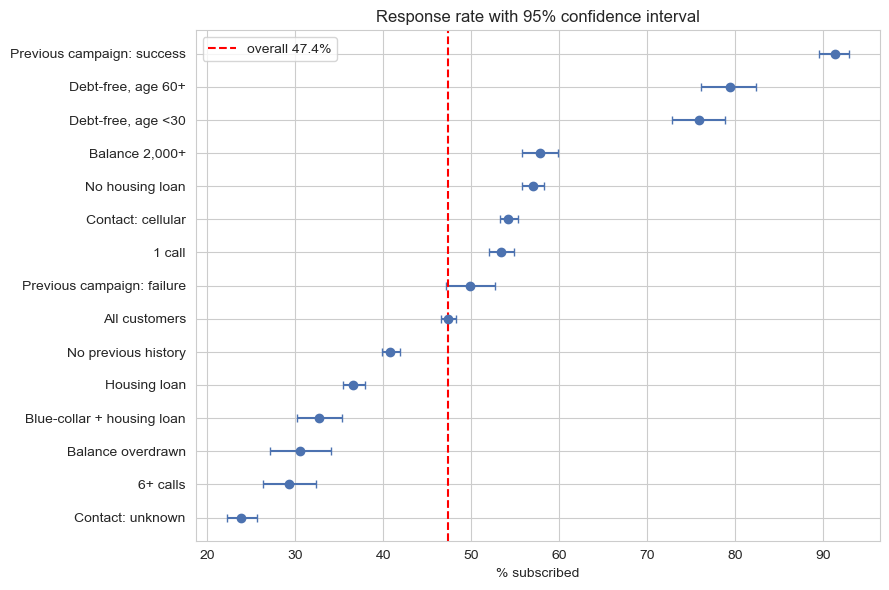


No housing loan minus housing loan: 20.4 points, 95% CI [18.6, 22.2]


In [8]:
k, n = df.deposit_flag.sum(), len(df); lo, hi = wilson(k, n)
print(f'Overall response rate: {k / n * 100:.1f}%  95% CI [{lo * 100:.1f}%, {hi * 100:.1f}%]  (n = {n:,}, width {(hi - lo) * 100:.1f} points)\n')
segs = {
 'All customers': df.index == df.index,
 'Previous campaign: success': df.poutcome == 'success',
 'Previous campaign: failure': df.poutcome == 'failure',
 'No previous history': df.poutcome == 'unknown',
 'No housing loan': df.housing == 'no',
 'Housing loan': df.housing == 'yes',
 'Contact: cellular': df.contact == 'cellular',
 'Contact: unknown': df.contact == 'unknown',
 '1 call': df.campaign == 1,
 '6+ calls': df.campaign >= 6,
 'Debt-free, age 60+': (df.debt_status == 'No loans') & (df.age_group == '60+'),
 'Debt-free, age <30': (df.debt_status == 'No loans') & (df.age_group == '<30'),
 'Blue-collar + housing loan': (df.job == 'blue-collar') & (df.housing == 'yes'),
 'Balance overdrawn': df.balance < 0,
 'Balance 2,000+': df.balance >= 2000,
}
out = []
for name, m in segs.items():
    kk, nn = df.deposit_flag[m].sum(), m.sum(); l, h = wilson(kk, nn)
    out.append(dict(segment=name, customers=nn, rate=kk / nn * 100, ci_low=l * 100, ci_high=h * 100, ci_width=(h - l) * 100))
ci = pd.DataFrame(out).set_index('segment').round(1)
print(ci.to_string())
t = ci.sort_values('rate')
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(t.rate, range(len(t)), xerr=[t.rate - t.ci_low, t.ci_high - t.rate], fmt='o', color='#4C72B0', capsize=3)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.axvline(BASE, color='red', ls='--', label=f'overall {BASE:.1f}%'); ax.legend()
ax.set_title('Response rate with 95% confidence interval'); ax.set_xlabel('% subscribed'); plt.tight_layout(); plt.show()
# difference between two proportions: housing loan vs no housing loan
a, b = df[df.housing == 'no'].deposit_flag, df[df.housing == 'yes'].deposit_flag
d = a.mean() - b.mean(); se = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b))
print(f'\nNo housing loan minus housing loan: {d * 100:.1f} points, 95% CI [{(d - 1.96 * se) * 100:.1f}, {(d + 1.96 * se) * 100:.1f}]')

**Observation / Interpretation**
* Overall response is **47.4%**, 95% CI **[46.5%, 48.3%]**, a precise estimate (± 0.9 points).
* Interval width grows as groups shrink: about 2 points for groups of thousands, 5–7 points for groups of a few hundred to 1,300 (e.g. debt-free age 60+: 79.4% [76.1, 82.3]; overdrawn: 30.5% [27.1, 34.1]).
* **Previous success 91.3% [89.5, 92.9]** and **unknown contact 23.8% [22.2, 25.6]** are far from the overall rate and their intervals do not come near it, so these gaps are not sampling noise.
* **No housing loan minus housing loan = 20.4 points, 95% CI [18.6, 22.2]**: a difference of at least 18 points is well supported.
* 6+ calls: 29.3% [26.3, 32.4] vs 1 call: 53.4% [52.0, 54.8]: the intervals do not overlap.

**Business insight:** the headline findings are reliable enough to plan around. When quoting a segment rate to management, give the interval; for small segments, the range is wide (for example ±3 points for 660 customers).

### 3.2 Numeric business metrics

In [9]:
y = df.duration
m, se = y.mean(), y.std(ddof=1) / np.sqrt(len(y)); tcrit = stats.t.ppf(.975, len(y) - 1)
print(f'Mean call duration: {m:.1f} s  95% t-CI [{m - tcrit * se:.1f}, {m + tcrit * se:.1f}]  (= {m / 60:.2f} minutes)')
for grp in ['yes', 'no']:
    v = df.loc[df.deposit == grp, 'duration']; mm, ss = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
    print(f'  mean duration, deposit={grp}: {mm:.0f} s  CI [{mm - 1.96 * ss:.0f}, {mm + 1.96 * ss:.0f}]')
bal = df.balance.values
meds = np.array([np.median(rng.choice(bal, len(bal))) for _ in range(3000)])
print(f'\nMedian balance: {np.median(bal):.0f}  95% bootstrap CI [{np.percentile(meds, 2.5):.0f}, {np.percentile(meds, 97.5):.0f}]')
print(f'(mean balance {bal.mean():.0f} for comparison; its t-CI [{bal.mean() - 1.96 * bal.std(ddof=1) / np.sqrt(len(bal)):.0f}, {bal.mean() + 1.96 * bal.std(ddof=1) / np.sqrt(len(bal)):.0f}] is pulled up by a few large balances)')
# proxy cost per subscriber (ASSUMPTION-BASED: 0.50 per call-minute)
cost, sub = df.estimated_campaign_cost.values, df.deposit_flag.values
bs = []
for _ in range(1500):
    i = rng.integers(0, len(df), len(df)); bs.append(cost[i].sum() / sub[i].sum())
print(f'\nProxy cost per subscriber (assumes 0.50 per call-minute): {cost.sum() / sub.sum():.2f}  95% bootstrap CI [{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]')

Mean call duration: 370.5 s  95% t-CI [364.1, 376.9]  (= 6.17 minutes)
  mean duration, deposit=yes: 534 s  CI [523, 544]
  mean duration, deposit=no: 223 s  CI [218, 229]

Median balance: 551  95% bootstrap CI [542, 558]
(mean balance 1520 for comparison; its t-CI [1460, 1579] is pulled up by a few large balances)

Proxy cost per subscriber (assumes 0.50 per call-minute): 6.52  95% bootstrap CI [6.40, 6.65]


**Interpretation:** average call lasts **6.17 minutes** (CI 364–377 seconds); subscribers talk about 534 s vs 223 s for non-subscribers, with non-overlapping intervals. The *median* balance is **551 [542, 558]**; the mean balance 1,520 [1,460, 1,579] is inflated by a few large accounts, which is why the median is the better headline. Under the assumed 0.50 per call-minute, the proxy cost per subscriber is **6.52 [6.40, 6.65]**. This interval reflects sampling noise only; it says nothing about whether 0.50 is the right price per minute, so the bank's real cost per minute must replace it before the figure is used.

### 3.3 Marketing channel ROI (bootstrap, resampling campaigns)

              campaigns  pooled_roi_pct  ci_low  ci_high
channel                                                 
Paid Search          18           228.0   154.0    323.0
Referral             16           295.0   176.0    473.0
Email                11           313.0   142.0    619.0
Ppc                  22           353.0   215.0    564.0
Social Media         16           379.0   221.0    604.0


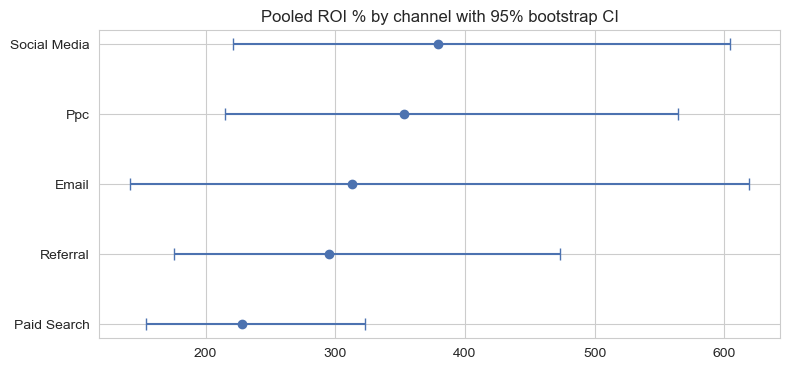


Share of bootstrap draws where Social Media ROI beats Paid Search ROI: 94.3 %


In [10]:
chs = [c for c in camp.Marketing_channel.unique() if c != 'Unknown']
rows, draws = [], {}
for ch in chs:
    g = camp[camp.Marketing_channel == ch]; sp, rv = g.Spend.values, g.Revenue.values
    bs = []
    for _ in range(5000):
        i = rng.integers(0, len(g), len(g)); bs.append((rv[i].sum() - sp[i].sum()) / sp[i].sum() * 100)
    draws[ch] = bs
    rows.append(dict(channel=ch, campaigns=len(g), pooled_roi_pct=(rv.sum() - sp.sum()) / sp.sum() * 100, ci_low=np.percentile(bs, 2.5), ci_high=np.percentile(bs, 97.5)))
cc = pd.DataFrame(rows).set_index('channel').round(0).sort_values('pooled_roi_pct')
print(cc.to_string())
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(cc.pooled_roi_pct, range(len(cc)), xerr=[cc.pooled_roi_pct - cc.ci_low, cc.ci_high - cc.pooled_roi_pct], fmt='o', capsize=4, color='#4C72B0')
ax.set_yticks(range(len(cc))); ax.set_yticklabels(cc.index); ax.set_title('Pooled ROI % by channel with 95% bootstrap CI'); plt.tight_layout(); plt.show()
print('\nShare of bootstrap draws where Social Media ROI beats Paid Search ROI:', round(np.mean(np.array(draws['Social Media']) > np.array(draws['Paid Search'])) * 100, 1), '%')

**Interpretation:** the intervals are very wide and overlap heavily (for example Email 142–619%, PPC 215–564%, Paid Search 154–323%), which matches the failed test in 2.5. Social Media beat Paid Search in 94% of bootstrap resamples, but that pair was chosen *after* looking at the data (best vs worst), so this is suggestive, not proof.

**Business insight:** with 11–22 campaigns per channel, channel ROI is too uncertain to rank. Log spend and revenue for every campaign (ideally with a campaign ID on each customer contact) to build real evidence.

## 4. Feature engineering

Each feature below starts from a Sprint 1–2 finding and has a stated business purpose. Several are bands of numeric columns, because Sprint 2 showed the relationships are not straight lines (age is U-shaped, contact frequency drops after about 3 calls) and because `pdays = -1` is a code, not a number.

In [11]:
f = df[['customer_id'] + list(core.columns.drop('customer_id'))].copy()
f['age_group']            = df.age_group
f['balance_tier']         = df.balance_tier
f['balance_log']          = np.sign(df.balance) * np.log1p(df.balance.abs())
f['debt_status']          = df.debt_status
f['contact_frequency_band'] = df.contact_frequency_band
f['previously_contacted'] = np.where(df.pdays > -1, 'Yes', 'No')
f['previous_success']     = np.where(df.poutcome == 'success', 'Yes', 'No')
f['contact_channel_known'] = np.where(df.contact != 'unknown', 'Yes', 'No')
f['quarter']              = df.month.map({m: f'Q{i // 3 + 1}' for i, m in enumerate(['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'])})
f['day_period']           = pd.cut(df.day, [0, 10, 20, 31], labels=['early (1-10)', 'mid (11-20)', 'late (21-31)']).astype(str)
f['call_duration_band']   = pd.cut(df.duration, [0, 120, 300, 600, np.inf], labels=['<2 min', '2-5 min', '5-10 min', '10+ min']).astype(str)
new_cols = ['age_group', 'balance_tier', 'balance_log', 'debt_status', 'contact_frequency_band', 'previously_contacted',
            'previous_success', 'contact_channel_known', 'quarter', 'day_period', 'call_duration_band']
print('rows:', len(f), '| original columns:', core.shape[1], '| engineered columns added:', len(new_cols), '| nulls in new columns:', int(f[new_cols].isna().sum().sum()))
print(f[['customer_id', 'age', 'balance', 'balance_log'] + [c for c in new_cols if c != 'balance_log']].head(5).to_string(index=False))
print(f"\nBalance skew before log transform: {df.balance.skew():.2f}  ->  after signed-log: {f.balance_log.skew():.2f}")
for c in ['previous_success', 'contact_channel_known', 'quarter', 'day_period']:
    print(f'\n{c}:', f[c].value_counts().to_dict())
f.to_csv(f'{DATA_DIR}/bank_features_engineered.csv', index=False)
print('\nSaved bank_features_engineered.csv', f.shape)

rows: 11162 | original columns: 18 | engineered columns added: 11 | nulls in new columns: 0
 customer_id  age  balance  balance_log age_group balance_tier  debt_status contact_frequency_band previously_contacted previous_success contact_channel_known quarter   day_period call_duration_band
           1 59.0   2343.0     7.759614     50-59         High Housing only                      1                   No               No                    No      Q2 early (1-10)            10+ min
           2 56.0     45.0     3.828641     50-59          Low     No loans                      1                   No               No                    No      Q2 early (1-10)            10+ min
           3 41.0   1270.0     7.147559     40-49       Medium Housing only                      1                   No               No                    No      Q2 early (1-10)            10+ min
           4 55.0   2476.0     7.814803     50-59         High Housing only                      1              

In [12]:
doc = pd.DataFrame([
 ('age_group', 'age cut at 30/40/50/60', 'Target younger and older customers differently', 'Age has near-zero linear correlation with deposit (0.04) but a U-shaped response (60% under 30, 41-44% for 30-59, 77% for 60+). A band captures what a straight-line measure misses.', 'Under-30 and 60+ are the responsive ages.'),
 ('balance_tier', 'balance: <0, 0-500, 500-2,000, 2,000+', 'Gauge financial capacity at a glance', 'Raw balance is extremely skewed (8.3); tiers give stable groups and an easy rule for call lists.', 'Higher tier -> higher response.'),
 ('balance_log', 'sign(balance) * log(1 + |balance|)', 'Make balance usable in correlations and averages', 'Reduces skew so a few large accounts do not dominate statistics.', 'Compare balances on a ratio-like scale.'),
 ('debt_status', 'housing / personal loan combination', 'Summarise debt burden in one field', 'Two yes/no columns carry one idea (debt load); response falls from 59.6% (no loans) to 31.7% (both).', 'Any loan lowers response; both lowest.'),
 ('contact_frequency_band', 'campaign cut at 1/2/3/4-5/6+', 'Set a contact-limit policy', 'Response drops from 53% (1 call) to 29% (6+); bands show where returns fade.', 'Diminishing returns after about 3 calls.'),
 ('previously_contacted', 'pdays > -1', 'Separate existing from brand-new relationships', 'pdays = -1 is a code, not a number; averaging it is meaningless. A flag uses it correctly.', 'Yes = warmer lead.'),
 ('previous_success', 'poutcome == success', 'Isolate the warmest leads', '91% of previous successes subscribe again; the flag makes the group easy to extract.', 'Yes = call first.'),
 ('contact_channel_known', 'contact != unknown', 'Flag records with missing channel information', 'Unknown-channel customers respond at 24% vs 54% cellular; the gap may be a data-capture issue.', 'No = data-quality / weak-lead flag.'),
 ('quarter', 'month -> Q1..Q4', 'Plan campaign timing in seasons', 'Months are noisy and uneven; quarters give larger groups.', 'Season-level planning.'),
 ('day_period', 'day -> early/mid/late month', 'Test pay-cycle timing', 'Customers may be more receptive near pay-days; included to test, evaluated honestly in section 6.', 'To be judged by evidence.'),
 ('call_duration_band', 'duration cut at 2/5/10 min', 'Describe call quality after the call', 'Strongest single signal (9% under 2 min vs 85% over 10) but known only AFTER the call, so NOT usable for choosing whom to call.', 'Post-call diagnostic only.'),
], columns=['feature', 'logic', 'business_purpose', 'justification', 'interpretation'])
doc.to_csv(f'{DATA_DIR}/feature_documentation.csv', index=False)
print(doc[['feature', 'logic', 'business_purpose']].to_string(index=False))
print('\nFull justification text saved to feature_documentation.csv')

               feature                                 logic                                 business_purpose
             age_group                age cut at 30/40/50/60   Target younger and older customers differently
          balance_tier balance: <0, 0-500, 500-2,000, 2,000+             Gauge financial capacity at a glance
           balance_log    sign(balance) * log(1 + |balance|) Make balance usable in correlations and averages
           debt_status   housing / personal loan combination               Summarise debt burden in one field
contact_frequency_band          campaign cut at 1/2/3/4-5/6+                       Set a contact-limit policy
  previously_contacted                            pdays > -1   Separate existing from brand-new relationships
      previous_success                   poutcome == success                        Isolate the warmest leads
 contact_channel_known                    contact != unknown    Flag records with missing channel information
          

### Feature documentation

| Feature | Logic | Business purpose | Justification | Interpretation |
|---|---|---|---|---|
| `age_group` | age cut at 30/40/50/60 | Target younger and older customers differently | Age has near-zero linear correlation with deposit (0.04) but a U-shaped response (60% under 30, 41-44% for 30-59, 77% for 60+). A band captures what a straight-line measure misses. | Under-30 and 60+ are the responsive ages. |
| `balance_tier` | balance: <0, 0-500, 500-2,000, 2,000+ | Gauge financial capacity at a glance | Raw balance is extremely skewed (8.3); tiers give stable groups and an easy rule for call lists. | Higher tier -> higher response. |
| `balance_log` | sign(balance) * log(1 + |balance|) | Make balance usable in correlations and averages | Reduces skew so a few large accounts do not dominate statistics. | Compare balances on a ratio-like scale. |
| `debt_status` | housing / personal loan combination | Summarise debt burden in one field | Two yes/no columns carry one idea (debt load); response falls from 59.6% (no loans) to 31.7% (both). | Any loan lowers response; both lowest. |
| `contact_frequency_band` | campaign cut at 1/2/3/4-5/6+ | Set a contact-limit policy | Response drops from 53% (1 call) to 29% (6+); bands show where returns fade. | Diminishing returns after about 3 calls. |
| `previously_contacted` | pdays > -1 | Separate existing from brand-new relationships | pdays = -1 is a code, not a number; averaging it is meaningless. A flag uses it correctly. | Yes = warmer lead. |
| `previous_success` | poutcome == success | Isolate the warmest leads | 91% of previous successes subscribe again; the flag makes the group easy to extract. | Yes = call first. |
| `contact_channel_known` | contact != unknown | Flag records with missing channel information | Unknown-channel customers respond at 24% vs 54% cellular; the gap may be a data-capture issue. | No = data-quality / weak-lead flag. |
| `quarter` | month -> Q1..Q4 | Plan campaign timing in seasons | Months are noisy and uneven; quarters give larger groups. | Season-level planning. |
| `day_period` | day -> early/mid/late month | Test pay-cycle timing | Customers may be more receptive near pay-days; included to test, evaluated honestly in section 6. | To be judged by evidence. |
| `call_duration_band` | duration cut at 2/5/10 min | Describe call quality after the call | Strongest single signal (9% under 2 min vs 85% over 10) but known only AFTER the call, so NOT usable for choosing whom to call. | Post-call diagnostic only. |

**Not engineered on purpose:** hand-made "priority" scores combining age, debt and history were *not* added as features, because they would be built from the same data they are later judged on. Section 5 builds such segments on a training split only.

**Observation:** the signed-log transform reduces the balance skew from 8.28 to −1.81: much closer to symmetric but now slightly left-skewed (it over-corrects a little). 11 columns were added with no missing values, producing a 29-column file.

## 5. Feature evaluation: before vs after

### 5.1 Does the signal become easier to see?

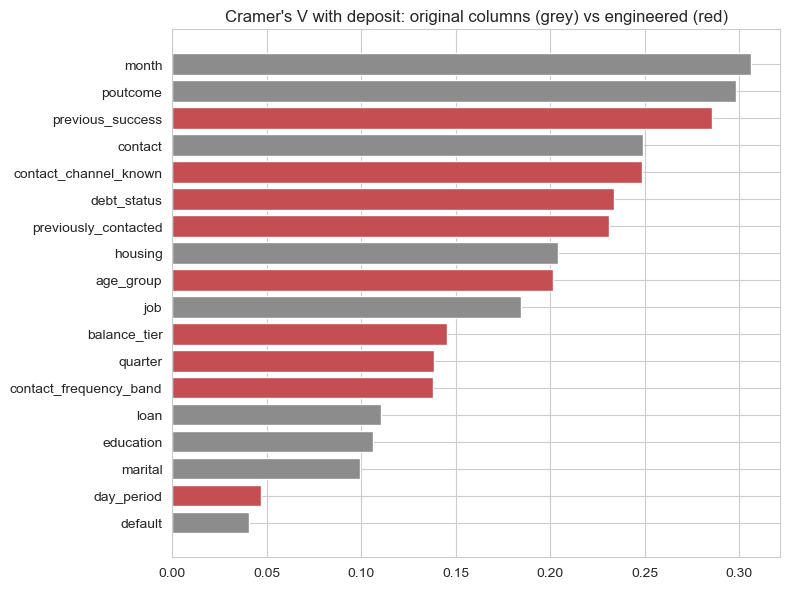

month                     0.306
poutcome                  0.298
previous_success          0.286
contact                   0.249
contact_channel_known     0.249
debt_status               0.234
previously_contacted      0.231
housing                   0.204
age_group                 0.201
job                       0.185
balance_tier              0.145
quarter                   0.138
contact_frequency_band    0.138
loan                      0.111
education                 0.106
marital                   0.099
day_period                0.047
default                   0.041

Raw numeric column vs the band made from it (different scales, but both show how visible the signal is):
  age       |Pearson r| = 0.036   ->   age_group: Cramer's V = 0.201
  balance   |Pearson r| = 0.082   ->   balance_tier: Cramer's V = 0.145
  campaign  |Pearson r| = 0.128   ->   contact_frequency_band: Cramer's V = 0.138


In [13]:
before_cat = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
after_cat = ['age_group', 'balance_tier', 'debt_status', 'contact_frequency_band', 'previously_contacted', 'previous_success',
             'contact_channel_known', 'quarter', 'day_period']
F = f.copy(); F['deposit_flag'] = df.deposit_flag.values
V = {c: cramers_v(pd.crosstab(F[c], F.deposit)) for c in before_cat + after_cat}
vs = pd.Series(V).sort_values()
colors = ['#C44E52' if i in after_cat else '#8C8C8C' for i in vs.index]
fig, ax = plt.subplots(figsize=(8, 6)); ax.barh(vs.index, vs.values, color=colors)
ax.set_title("Cramer's V with deposit: original columns (grey) vs engineered (red)"); plt.tight_layout(); plt.show()
print(vs.sort_values(ascending=False).round(3).to_string())
print('\nRaw numeric column vs the band made from it (different scales, but both show how visible the signal is):')
for raw, band in [('age', 'age_group'), ('balance', 'balance_tier'), ('campaign', 'contact_frequency_band')]:
    print(f"  {raw:9s} |Pearson r| = {abs(np.corrcoef(df[raw], df.deposit_flag)[0, 1]):.3f}   ->   {band}: Cramer's V = {V[band]:.3f}")

**Observation:** the bands make the signal in numeric columns visible: `age` has only |r| = 0.036 with the outcome, but `age_group` reaches V = 0.20; `balance_tier` (0.145) vs raw balance (0.082). `previous_success` (V = 0.29) retains almost all the information in the four-category `poutcome` (0.30) in a simpler form. `contact_channel_known` matches `contact` (0.25) exactly. `quarter` (0.14) is much weaker than `month` (0.31) and `day_period` (0.05) is near the useless `default` flag.

**Interpretation:** r (linear) and V (any pattern) are on different scales, so this comparison shows *visibility of signal*, not accuracy. The clearest gain is for age, where a linear measure sees almost nothing.

### 5.2 Does ranking customers improve? (held-out test, 10 random 70/30 splits)
A transparent additive log-odds model (naive-Bayes style) ranks customers using **pre-call information only**. AUC 0.5 means no better than chance, 1.0 means perfect ranking.

Held-out AUC (10 random 70/30 splits). 0.5 = no better than guessing, 1.0 = perfect.

                                                       mean_test_AUC      sd  gain_vs_previous_step
BEFORE: 9 original categorical columns                        0.7449  0.0078                    NaN
+ age_group                                                   0.7498  0.0068                 0.0049
+ balance_tier                                                0.7538  0.0073                 0.0040
+ debt_status                                                 0.7471  0.0079                -0.0067
+ contact_frequency_band                                      0.7519  0.0079                 0.0049
+ previously_contacted                                        0.7521  0.0080                 0.0002
+ previous_success                                            0.7529  0.0082                 0.0008
+ contact_channel_known                                       0.7547  0.0081                 0.0018
+ quarter     

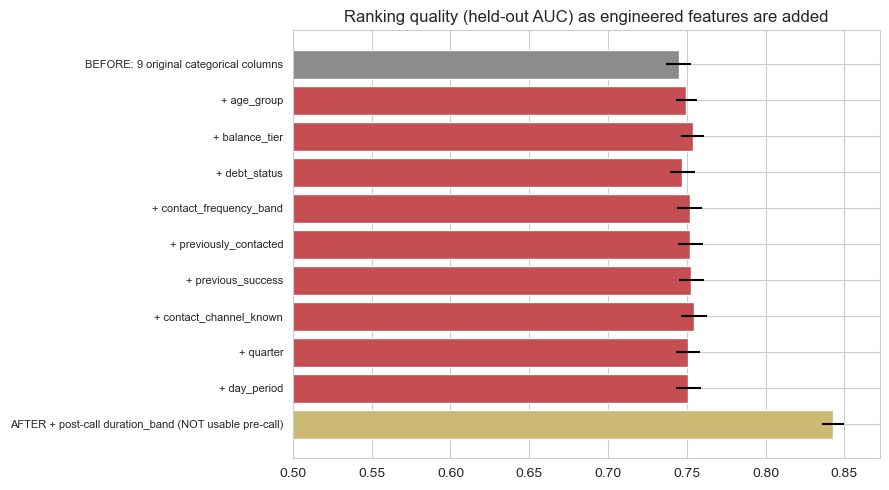

In [14]:
def nb_fit(train, feats, a=1.0):
    y = train.deposit_flag; ny, nn = y.sum(), (1 - y).sum(); tables = {}
    for ft in feats:
        col = train[ft].astype(str); cats = col.unique(); K = len(cats)
        yes, no = col[y == 1].value_counts(), col[y == 0].value_counts()
        tables[ft] = {c: np.log((yes.get(c, 0) + a) / (ny + a * K)) - np.log((no.get(c, 0) + a) / (nn + a * K)) for c in cats}
    return np.log(ny / nn), tables
def nb_score(d, prior, tables):
    s = np.full(len(d), prior, dtype=float)
    for ft, t in tables.items(): s += d[ft].astype(str).map(t).fillna(0).values
    return s
def auc_of(score, y):
    pos, neg = score[y == 1], score[y == 0]
    return stats.mannwhitneyu(pos, neg).statistic / (len(pos) * len(neg))
def capture(score, y, frac):
    k = int(len(y) * frac); idx = np.argsort(-score)[:k]; return y[idx].sum() / y.sum()

steps = [('BEFORE: 9 original categorical columns', before_cat)]
added = []
for ft in ['age_group', 'balance_tier', 'debt_status', 'contact_frequency_band', 'previously_contacted', 'previous_success', 'contact_channel_known', 'quarter', 'day_period']:
    added.append(ft); steps.append((f'+ {ft}', before_cat + list(added)))
steps.append(('AFTER + post-call duration_band (NOT usable pre-call)', before_cat + added + ['call_duration_band']))

res = {n: [] for n, _ in steps}; cap30, cap50, cap30_b, cap50_b = [], [], [], []
for seed in range(10):
    r = np.random.default_rng(seed); idx = r.permutation(len(F)); cut = int(len(F) * .7)
    tr, te = F.iloc[idx[:cut]], F.iloc[idx[cut:]]
    for n, feats in steps:
        pr, tb = nb_fit(tr, feats); res[n].append(auc_of(nb_score(te, pr, tb), te.deposit_flag.values))
    pr, tb = nb_fit(tr, before_cat + added); s = nb_score(te, pr, tb); cap30.append(capture(s, te.deposit_flag.values, .3)); cap50.append(capture(s, te.deposit_flag.values, .5))
    pr, tb = nb_fit(tr, before_cat); s = nb_score(te, pr, tb); cap30_b.append(capture(s, te.deposit_flag.values, .3)); cap50_b.append(capture(s, te.deposit_flag.values, .5))
tab = pd.DataFrame({'mean_test_AUC': {n: np.mean(v) for n, v in res.items()}, 'sd': {n: np.std(v) for n, v in res.items()}})
tab['gain_vs_previous_step'] = tab.mean_test_AUC.diff()
print('Held-out AUC (10 random 70/30 splits). 0.5 = no better than guessing, 1.0 = perfect.\n')
print(tab.round(4).to_string())
print(f"\nIf the bank called only the top-ranked customers (held-out data):")
print(f"  BEFORE features: top 30% of customers capture {np.mean(cap30_b) * 100:.1f}% of subscribers; top 50% capture {np.mean(cap50_b) * 100:.1f}%")
print(f"  AFTER  features: top 30% of customers capture {np.mean(cap30) * 100:.1f}% of subscribers; top 50% capture {np.mean(cap50) * 100:.1f}%")
fig, ax = plt.subplots(figsize=(9, 5)); t = tab.mean_test_AUC
ax.barh(range(len(t)), t.values, xerr=tab.sd.values, color=['#8C8C8C'] + ['#C44E52'] * (len(t) - 2) + ['#CCB974'])
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(.5, max(t.values) + .03)
ax.set_title('Ranking quality (held-out AUC) as engineered features are added'); plt.tight_layout(); plt.show()

**Observation**
* Original 9 categorical columns: AUC **0.745**. Adding all pre-call engineered features: about **0.751**, a gain of only ~0.006, smaller than the split-to-split spread (± 0.008).
* The helpful additions are `age_group` (+0.005), `balance_tier` (+0.004), `contact_frequency_band` (+0.005) and `contact_channel_known` (+0.002). `debt_status` (−0.007) and `quarter` (−0.004) slightly *hurt* because they repeat information already in `housing`/`loan` and `month`; `day_period` and `previously_contacted` add essentially nothing.
* Calling only the top-ranked 30% of customers captures about 49% of subscribers (top 50%: 69%), versus 48.6% and 68.5% before.
* Adding the **post-call** duration band lifts AUC to 0.84, a reminder of how much of the outcome is determined during the call, which cannot be used for pre-call selection.

**Interpretation:** the original columns already carry most of the available pre-call information, so engineered features barely improve *ranking accuracy*. Their value lies elsewhere (5.3). Pre-call information gives a useful but modest edge (lift about 1.6 for the top 30%); no pre-call rule will find every subscriber.

### 5.3 Do engineered segments give clearer, more usable customer groups?

In [15]:
F['segment'] = F.age_group + ' | ' + F.debt_status + ' | prev. contacted: ' + F.previously_contacted
r = np.random.default_rng(7); idx = r.permutation(len(F)); cut = int(len(F) * .7); tr, te = F.iloc[idx[:cut]], F.iloc[idx[cut:]]
seg = tr.groupby('segment').agg(n=('deposit_flag', 'size'), rate=('deposit_flag', 'mean')).query('n >= 50').sort_values('rate', ascending=False)
seg['cum_share'] = seg.n.cumsum() / len(tr)
top = seg[seg.cum_share <= .30].index
tt = te[te.segment.isin(top)]
print(f'{len(seg)} segments with >= 50 training customers. The {len(top)} best segments (about 30% of training customers) were chosen on the TRAINING split only.')
print(f'On the unseen test split these segments hold {len(tt) / len(te) * 100:.1f}% of customers and respond at {tt.deposit_flag.mean() * 100:.1f}% '
      f'(overall {te.deposit_flag.mean() * 100:.1f}%), capturing {tt.deposit_flag.sum() / te.deposit_flag.sum() * 100:.1f}% of all test subscribers.')
jb = tr.groupby('job').deposit_flag.mean().sort_values(ascending=False); jn = tr.groupby('job').size()
top_jobs = []; cs = 0
for j in jb.index:
    if cs + jn[j] / len(tr) <= .30: top_jobs.append(j); cs += jn[j] / len(tr)
tj = te[te.job.isin(top_jobs)]
print(f'BEFORE (job only): best jobs {top_jobs} hold {len(tj) / len(te) * 100:.1f}% of test customers, respond at {tj.deposit_flag.mean() * 100:.1f}%, capture {tj.deposit_flag.sum() / te.deposit_flag.sum() * 100:.1f}% of subscribers.')
print('\nTop 6 engineered segments on the TRAINING split, and how they did on the TEST split:')
chk = seg.head(6).join(te.groupby('segment').deposit_flag.agg(test_n='size', test_rate='mean'))
chk['rate'] = (chk.rate * 100).round(1); chk['test_rate'] = (chk.test_rate * 100).round(1)
print(chk[['n', 'rate', 'test_n', 'test_rate']].rename(columns={'n': 'train_n', 'rate': 'train_rate_%', 'test_rate': 'test_rate_%'}).to_string())

26 segments with >= 50 training customers. The 10 best segments (about 30% of training customers) were chosen on the TRAINING split only.
On the unseen test split these segments hold 24.8% of customers and respond at 74.5% (overall 47.2%), capturing 39.1% of all test subscribers.
BEFORE (job only): best jobs ['student', 'retired', 'unemployed', 'unknown', 'admin.', 'housemaid'] hold 28.8% of test customers, respond at 57.0%, capture 34.7% of subscribers.

Top 6 engineered segments on the TRAINING split, and how they did on the TEST split:
                                         train_n  train_rate_%  test_n  test_rate_%
segment                                                                            
<30 | No loans | prev. contacted: Yes        180          86.7      81         80.2
60+ | No loans | prev. contacted: Yes        185          85.4      75         92.0
40-49 | No loans | prev. contacted: Yes      164          83.5      71         71.8
50-59 | No loans | prev. contacted:

**Observation:** segments built from three engineered features (age group × debt status × previously contacted) were selected on the **training split only**. On unseen customers, the 10 best segments cover 24.8% of customers, respond at **74.5%** (overall 47.2%) and capture **39.1%** of all subscribers (lift 1.58). Picking the best *jobs* instead covers 28.8% of customers, responds at 57.0% and captures 34.7% (lift 1.21). The top training segments held up on test data (for example 86.7% → 80.2%, 85.4% → 92.0%), though individual test segments contain only 57–138 customers.

**Interpretation / honest verdict:** combining several engineered features gives much sharper, stable targeting groups than a single raw column such as job. Part of this gain simply comes from combining three signals rather than one; the engineered bands make that combination easy to define and explain.

### Feature evaluation: summary
| Feature | Verdict | Evidence |
|---|---|---|
| `age_group` | **Keep** | Captures the U-shape; V 0.20 vs |r| 0.04; +0.005 AUC |
| `balance_tier` | **Keep** | V 0.145 vs 0.082; +0.004 AUC |
| `contact_frequency_band` | **Keep** | Shows fatigue after ~3 calls; +0.005 AUC |
| `previous_success` / `previously_contacted` | **Keep for segments** | Simple flags for warm leads; AUC gain ≈ 0 because `poutcome` already holds it |
| `contact_channel_known` | **Keep as a data-quality flag** | Same signal as `contact`; +0.002 AUC |
| `debt_status` | **Keep for segments, not alongside housing + loan in a model** | V 0.23; redundant with `housing` and `loan` (−0.007 AUC) |
| `balance_log` | Keep for correlation / regression use | Skew 8.28 → −1.81 |
| `quarter` | **Drop** | Weaker than `month` (0.14 vs 0.31), −0.004 AUC |
| `day_period` | **Drop** | V = 0.05, AUC gain ≈ 0 |
| `call_duration_band` | **Post-call diagnostic only** | Strong (AUC 0.84) but not known before calling |

**Before vs after, in one line:** feature engineering gave a modest ranking gain (+0.006 AUC) but clearly better customer segmentation and easier-to-explain rules; two of the eleven features did not earn their place.

## 6. Final business recommendations

Every recommendation cites evidence from Sprints 1–3. Because the data are observational, recommendations framed as "test" should be run as controlled pilots before being rolled out.

In [16]:
ev = []
def add(claim, mask_a, mask_b=None):
    ka, na = df.deposit_flag[mask_a].sum(), mask_a.sum(); la, ha = wilson(ka, na)
    row = dict(finding=claim, customers=int(na), rate_pct=round(ka / na * 100, 1), ci=f'[{la * 100:.1f}, {ha * 100:.1f}]')
    ev.append(row)
add('Previous campaign success', df.poutcome == 'success')
add('No previous history', df.poutcome == 'unknown')
add('Debt-free AND (age 60+ or <30)', (df.debt_status == 'No loans') & df.age_group.isin(['60+', '<30']))
add('Housing loan', df.housing == 'yes')
add('Contact method unknown', df.contact == 'unknown')
add('1-2 calls', df.campaign <= 2)
add('4+ calls', df.campaign >= 4)
add('Blue-collar + housing loan', (df.job == 'blue-collar') & (df.housing == 'yes'))
print(pd.DataFrame(ev).to_string(index=False))
call_cost_no = df.loc[df.deposit == 'no', 'estimated_campaign_cost'].sum() / df.estimated_campaign_cost.sum() * 100
extra = df[df.campaign >= 4]
print(f'\nCustomers receiving 4+ calls: {len(extra):,} ({len(extra) / len(df) * 100:.1f}% of customers); their response rate is {extra.deposit_flag.mean() * 100:.1f}% vs {df[df.campaign <= 3].deposit_flag.mean() * 100:.1f}% for 1-3 calls')
print(f'Proxy (assumption-based) call-time cost spent on customers who said no: {call_cost_no:.1f}%')

                       finding  customers  rate_pct           ci
     Previous campaign success       1063      91.3 [89.5, 92.9]
           No previous history       8357      40.8 [39.8, 41.9]
Debt-free AND (age 60+ or <30)       1420      77.5 [75.3, 79.6]
                  Housing loan       5281      36.6 [35.4, 37.9]
        Contact method unknown       2423      23.8 [22.2, 25.6]
                     1-2 calls       7831      50.6 [49.5, 51.7]
                      4+ calls       2013      35.2 [33.2, 37.3]
    Blue-collar + housing loan       1306      32.7 [30.2, 35.3]

Customers receiving 4+ calls: 2,013 (18.0% of customers); their response rate is 35.2% vs 50.1% for 1-3 calls
Proxy (assumption-based) call-time cost spent on customers who said no: 31.7%


| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Call previous successes first, and treat previously contacted customers as warm leads.** | Previous success converts at **91.3% [89.5, 92.9]** (n = 1,063); χ² V = 0.30, p = 1.4e-214. Previously contacted: 67.1% vs 40.7% (Sprint 2). |
| 2 | **Build the main acquisition list around debt-free customers aged 60+ or under 30.** | 1,420 customers (12.7% of the base) respond at **77.5% [75.3, 79.6]** vs 47.4% overall. On held-out data, the best engineered segments reach 74.5% and capture 39% of subscribers using 25% of contacts (vs 57.0% / 35% for the best jobs). |
| 3 | **Use a different offer, or lower priority, for customers with a housing loan, especially blue-collar workers; run an A/B test.** | Housing loan 36.6% vs 57.0%: gap **20.4 points [18.6, 22.2]**. Blue-collar with a housing loan: 32.7% [30.2, 35.3], n = 1,306 (11.7% of customers). They still convert at about one in three, so they should be pitched differently, not dropped. |
| 4 | **Pilot a cap of about 3 call attempts (or a channel switch after the third).** | 18.0% of customers (2,013) received 4+ calls and responded at **35.2% [33.2, 37.3]** vs 50.1% for 1–3 calls; 6+ calls: 29.3% [26.3, 32.4]. Proxy cost per subscriber rises from 5.61 (1 call) to 9.17 (6+). *This is an association; customers who refuse tend to be re-called, so only a pilot can show the effect of capping.* |
| 5 | **Audit how "contact method" is recorded before changing channel strategy.** | Unknown contact: **23.8% [22.2, 25.6]** vs 54.2% cellular (V = 0.25), and 92% of these records fall in May–June, so this may be a record-keeping or lead-source issue rather than a channel effect. Unknown-contact customers also cost about 2× more per subscriber (12.74 vs about 5.75, proxy). |
| 6 | **Spread or test May volume instead of cutting it blindly.** | May holds 25% of contacts but converts at 32.8%; month has the largest association (V = 0.31), but it is confounded with contact mix and campaign intensity, so a controlled test is needed. |
| 7 | **Track "calls ending under 2 minutes" as a quality KPI and investigate their causes (lead quality, script, timing).** | Calls under 2 minutes convert at 9.3% vs 85.1% for 10+; duration has d = 0.99 (largest effect found). Duration is post-call and its effect on conversion is not proven, so it is a diagnostic, not a targeting rule. |
| 8 | **Do not move marketing budget between channels on current evidence; collect campaign-level cost and revenue.** | Channel ROI differences are not significant (Kruskal–Wallis p = 0.73); intervals overlap widely (Email 142–619%). Spend vs revenue correlation was only +0.06 (Sprint 2). |
| 9 | **Replace the ROI assumptions with real figures and add a campaign ID to every customer contact.** | The 0.50 per minute / 200 per deposit inputs are illustrative. Without a shared key, customer outcomes cannot be tied to campaign cost, so real ROI per customer or channel cannot be computed. 31.7% of call-time cost (proxy) goes to customers who decline. |
| 10 | **Adopt the engineered features that earned their place** (`age_group`, `balance_tier`, `contact_frequency_band`, `previous_success`, `contact_channel_known`, `debt_status` for segments); drop `quarter` and `day_period`. | Section 5 evaluation table. |

**Expected value of targeting (realistic framing):** ranking customers with pre-call information improves the odds by roughly 1.6× in the top 30%, but contacting only the top half would still miss about 31% of subscribers. Use the ranking to set the *order* and the pitch, not to exclude customers outright.

## 7. Limitations
* **Observational data:** the associations do not prove that changing a factor (e.g. capping calls) will change the response.
* **Reused data:** Sprint 2 patterns were tested on the same customers; p-values are therefore optimistic. The hold-out evaluation in Section 5 is the safeguard, and it supports the main findings.
* **Large-sample caution:** significance is near-certain; effect sizes (V, d, η², probability of superiority) were used to judge importance.
* **Confounding:** month, contact method and campaign intensity move together, so their separate effects cannot be isolated here.
* **ROI:** customer-level values rest on assumed constants; the campaign table is small (88 rows, 5 without a channel) and unlinked to customers.
* **Model scope:** the log-odds model in 5.2 is a simple comparison tool; it double-counts correlated features and is not a production scoring model.
* **Duration** is post-call information.

## Task coverage map (Sprint 3 brief → section)
| Brief item | Section |
|---|---|
| 1 Statistical analysis (central tendency, dispersion, percentiles, IQR, skew, kurtosis, correlation, covariance) | 1 |
| 2 Hypothesis testing (chi-square, t-test / Mann–Whitney, ANOVA / Kruskal–Wallis; H0, H1, statistic, p, decision, interpretation) | 2 |
| 3 Confidence intervals | 3 |
| 4 Feature engineering (logic, purpose, justification, interpretation) | 4 + `feature_documentation.csv` |
| 5 Feature evaluation (before vs after) | 5 |
| 6 Final business recommendations | 6 |